<div style="background: linear-gradient(135deg, #123b5d, #1f6f8b); color: white; padding: 28px; border-radius: 12px;">
  <h1 style="margin: 0;">GBU 2301: Business Statistics</h1>
  <h2 style="margin: 8px 0 18px 0; font-weight: 400;">Week 7: Continuous Probability Distributions</h2>
  <p style="margin: 0; font-size: 1.05em;">Fall 2026 | Dr. Omer Cayirli | Assistant Professor of Finance</p>
</div>

Required reading: Anderson et al., Statistics for Business and Economics, 15th ed., Chapter 6

---

### Outline

* Continuous Random Variables and Probability Density
* Uniform Probability Distribution
* Normal Probability Distribution
* Student's $t$-Distribution: Introduction
* Normal Approximation of Binomial Probabilities
* Exponential Probability Distribution

---

### Continuous Random Variables

A continuous random variable can take any value within an interval or a collection of intervals.

| Variable | Possible values | Type |
|---|---|---|
| Number of calls in 10 minutes | $0,1,2,\ldots$ | Discrete |
| Time until the next call, in minutes | Any nonnegative value, such as $2.4$, $2.41$, $2.413$, $\ldots$ | Continuous |

* Discrete model: assign probability to each possible count.
* Continuous model: obtain probability from the area over an interval of values.
* Recording time to the nearest minute does not make the underlying waiting time discrete.

For a continuous model,

$$P(X=2)=0,\qquad\text{but }P(2<X<3)\text{ can be positive}.$$

A single exact value has zero probability; a range of values can have positive probability.

---

### Probability Density

The probability density function, $f(x)$, describes how probability is distributed over possible values.

* $f(x)\geq0$; the total area under the density is $1$.
* Probability over an interval: area under the density between its endpoints.
* Density height, $f(x)$, is not the probability $P(X=x)$.

Suppose a waiting time has constant density $0.10$ between $0$ and $10$ minutes, and zero elsewhere.

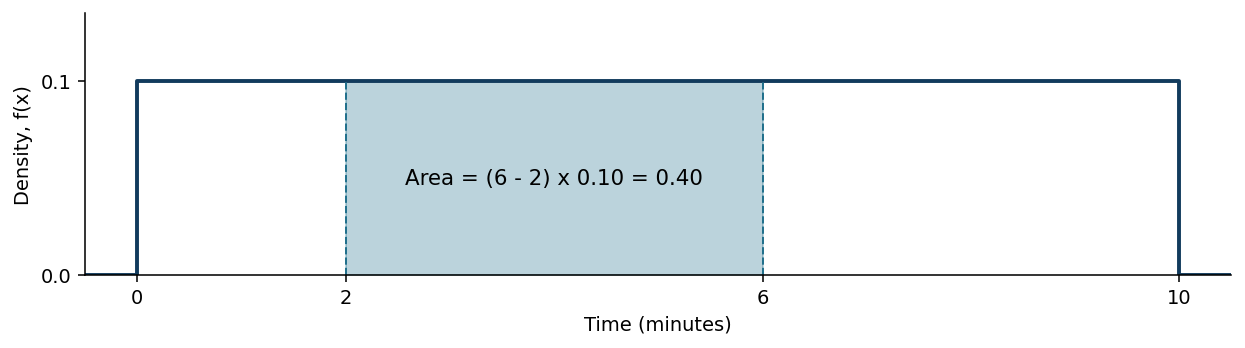

$$P(2\leq X\leq6)=(6-2)(0.10)=0.40.$$

At a single point, the interval has zero width, so its area is zero.

---

### Cumulative Probabilities

The cumulative distribution function gives the probability up to a specified value:

$$F(x)=P(X\leq x).$$

| Event | Probability |
|---|---|
| At most $b$ | $P(X\leq b)=F(b)$ |
| More than $b$ | $P(X>b)=1-F(b)$ |
| Between $a$ and $b$, where $a<b$ | $P(a<X\leq b)=F(b)-F(a)$ |

For the previous waiting-time example:

$$F(2)=(2-0)(0.10)=0.20,\qquad F(6)=(6-0)(0.10)=0.60.$$

$$P(2<X\leq6)=F(6)-F(2)=0.60-0.20=0.40.$$

$$P(X>6)=1-F(6)=1-0.60=0.40.$$

For continuous variables, including or excluding an endpoint does not change the probability:

$$P(a<X<b)=P(a\leq X\leq b).$$

---

### Uniform Probability Distribution

A continuous uniform distribution assigns equal probabilities to intervals of equal length within its support.

$$X\sim U(a,b),\qquad a<b.$$

$$f(x)=
\begin{cases}
\dfrac{1}{b-a}, & a\leq x\leq b,\\
0, & \text{otherwise}.
\end{cases}$$

* $a$: smallest possible value; $b$: largest possible value.
* Constant height: $1/(b-a)$.
* Total area: $(b-a)\times1/(b-a)=1$.

For $a\leq c<d\leq b$,

$$P(c\leq X\leq d)=\frac{d-c}{b-a}.$$

Probability is the selected interval's length divided by the full interval's length.

---

### Uniform Distribution: Delivery Time

Alpha Couriers models delivery time $X$ as uniformly distributed.

| Minimum time, $a$ | Maximum time, $b$ | Density within the interval |
|---:|---:|---:|
| 20 minutes | 40 minutes | $1/(40-20)=0.05$ |

Between 25 and 32 minutes:

$$P(25\leq X\leq32)=\frac{32-25}{40-20}=\frac7{20}=0.35.$$

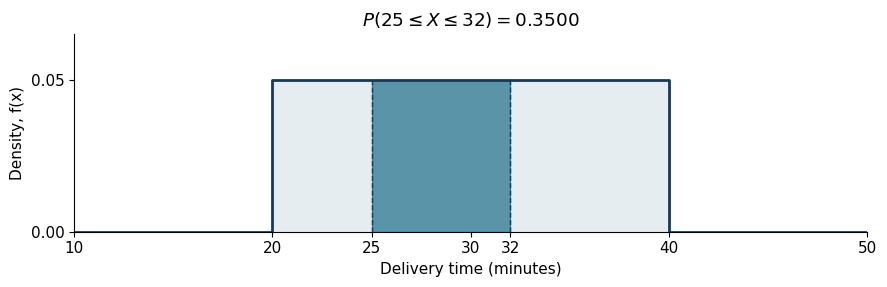

More than 35 minutes:

$$P(X>35)=\frac{40-35}{40-20}=\frac5{20}=0.25.$$

---

### Uniform Mean and Variance

For $X\sim U(a,b)$,

$$E(X)=\frac{a+b}{2},\qquad
\operatorname{Var}(X)=\frac{(b-a)^2}{12},\qquad
\sigma_X=\frac{b-a}{\sqrt{12}}.$$

* Mean: midpoint of the interval.
* Wider interval: greater variance and standard deviation.

First find $E(X^2)$, the probability-weighted average of $X^2$. For a continuous variable, integration replaces summation:

$$\begin{aligned}
E(X^2)&=\int_a^b x^2f(x)\,dx
=\frac{1}{b-a}\left[\frac{x^3}{3}\right]_a^b\\[4pt]
&=\frac{b^3-a^3}{3(b-a)}
=\frac{a^2+ab+b^2}{3}.
\end{aligned}$$

Subtract the squared mean:

$$\begin{aligned}
\operatorname{Var}(X)&=E(X^2)-[E(X)]^2
=\frac{a^2+ab+b^2}{3}-\frac{(a+b)^2}{4}\\[4pt]
&=\frac{4(a^2+ab+b^2)-3(a+b)^2}{12}\\[4pt]
&=\frac{a^2-2ab+b^2}{12}
=\frac{(b-a)^2}{12}.
\end{aligned}$$

For Alpha Couriers, $X\sim U(20,40)$:

$$E(X)=\frac{20+40}{2}=30\text{ minutes}.$$

$$\operatorname{Var}(X)=\frac{(40-20)^2}{12}
=\frac{400}{12}\approx33.33\text{ minutes}^2.$$

$$\sigma_X=\sqrt{\frac{400}{12}}\approx5.77\text{ minutes}.$$

---

### Uniform Probabilities: Delivery Time

$X\sim U(20,40)$; times in minutes. Run this cell to change the event.

$$P(25\leq X\leq 32)=\frac{(32-25)}{40-20}=0.3500=35.00\%.$$

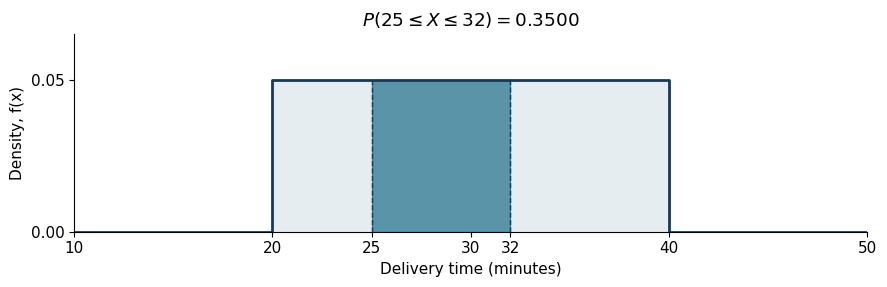

In [1]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def uniform_delivery_probability(kind, k=30, lower=25, upper=32):
    a, b = 20, 40
    def clip(x):
        return min(b, max(a, x))
    if kind == "between":
        segments = [(clip(lower), clip(upper))]
        event = rf"{lower:g}\leq X\leq {upper:g}"
    elif kind == "outside":
        segments = [(a, clip(lower)), (clip(upper), b)]
        event = rf"X<{lower:g}\ \mathrm{{or}}\ X>{upper:g}"
    elif kind == "le":
        segments = [(a, clip(k))]
        event = rf"X\leq {k:g}"
    elif kind == "ge":
        segments = [(clip(k), b)]
        event = rf"X\geq {k:g}"
    else:
        segments = []
        event = rf"X={k:g}"
    segments = [(left, right) for left, right in segments if right > left]
    width = sum(right-left for left, right in segments)
    return event, segments, width/(b-a)

def uniform_delivery_explorer():
    style = {"description_width": "initial"}
    event_control = widgets.Dropdown(
        options=[("Between two times", "between"),
                 ("At most a specified time", "le"),
                 ("At least a specified time", "ge"),
                 ("Outside two times", "outside"),
                 ("Exactly a specified time", "eq")],
        value="between", description="Event:", style=style,
        layout=widgets.Layout(width="430px", max_width="100%"))
    cutoff = widgets.IntSlider(
        value=30, min=10, max=50, description="Time (minutes):",
        continuous_update=False, style=style)
    bounds = widgets.IntRangeSlider(
        value=(25, 32), min=10, max=50, description="Times (minutes):",
        continuous_update=False, style=style)
    display(widgets.VBox([event_control, cutoff, bounds]))
    calculation_display = display(Markdown(""), display_id=True)
    graph_display = display(Markdown(""), display_id=True)

    def update(change=None):
        kind, k = event_control.value, cutoff.value
        lower, upper = bounds.value
        is_range = kind in ("between", "outside")
        cutoff.layout.display = "none" if is_range else ""
        bounds.layout.display = "" if is_range else "none"
        event, segments, probability = uniform_delivery_probability(
            kind, k, lower, upper)
        widths = "+".join(f"({right:g}-{left:g})" for left, right in segments) or "0"
        lines = [
            "### Uniform Probabilities: Delivery Time",
            r"$X\sim U(20,40)$; times in minutes. Run this cell to change the event.",
            rf"$$P({event})=\frac{{{widths}}}{{40-20}}"
            rf"={probability:.4f}={100*probability:.2f}\%.$$",
        ]
        if kind == "eq":
            lines.append("An exact time has zero width, so its probability is zero.")
        elif (is_range and (lower < 20 or upper > 40)) or (not is_range and (k < 20 or k > 40)):
            lines.append("Only the part of the event between 20 and 40 minutes contributes area.")
        calculation_display.update(Markdown("\n\n".join(lines)))
        with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                             "axes.spines.right": False}):
            fig, ax = plt.subplots(figsize=(9, 3))
            ax.fill_between([20, 40], 0, 0.05, color="#e6edf1")
            for left, right in segments:
                ax.fill_between([left, right], 0, 0.05, color="#1f6f8b", alpha=0.7)
                ax.vlines([left, right], 0, 0.05, color="#123b5d", ls="--", lw=1)
            ax.plot([10, 20, 20, 40, 40, 50], [0, 0, .05, .05, 0, 0],
                    color="#123b5d", lw=2)
            if kind == "eq":
                ax.plot(k, 0, "o", color="#d8872d")
            ax.set(xlim=(10, 50), ylim=(0, .065), xlabel="Delivery time (minutes)",
                   ylabel="Density, f(x)", yticks=[0, .05],
                   title=rf"$P({event})={probability:.4f}$")
            ax.set_xticks(sorted(set([10, 20, 30, 40, 50] +
                                     ([lower, upper] if is_range else [k]))))
            fig.tight_layout()
            graph_display.update(fig)
            plt.close(fig)

    for control in (event_control, cutoff, bounds):
        control.observe(update, names="value")
    update()
    return event_control, cutoff, bounds

uniform_controls = uniform_delivery_explorer()

### Exercise 1

Beta Couriers models delivery time $X$ as uniformly distributed.

| Minimum delivery time | Maximum delivery time |
|---:|---:|
| 18 minutes | 42 minutes |

a. What proportion of deliveries take between 24 and 33 minutes?

b. Calculate the mean and standard deviation of delivery time.

c. The company wants at least 90% of deliveries to arrive within its advertised time. What is the smallest whole-minute time it can advertise?

---

### Normal Probability Distribution

$$X\sim N(\mu,\sigma^2),\qquad \sigma>0.$$

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}
e^{-\frac12\left(\frac{x-\mu}{\sigma}\right)^2},
\qquad -\infty<x<\infty.$$

* Mean = median = mode = $\mu$; variance = $\sigma^2$.
* Symmetric about $\mu$: half the probability lies on each side.
* Changing $\mu$ shifts the curve; increasing $\sigma$ spreads it out.

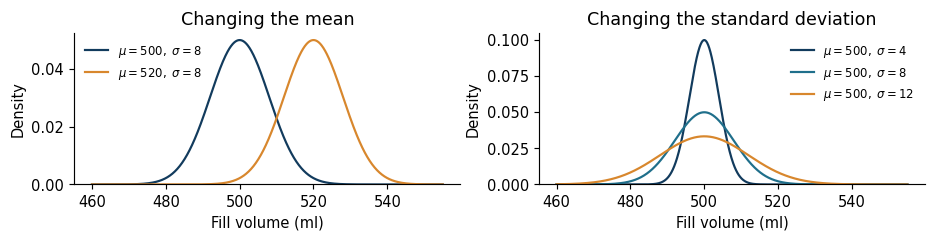

Probabilities are areas under the curve, not values of the density formula.

---

### Normal Distribution: Empirical Rule

For a normally distributed variable:

$$P(\mu-\sigma\leq X\leq\mu+\sigma)\approx0.6827,$$

$$P(\mu-2\sigma\leq X\leq\mu+2\sigma)\approx0.9545,$$

$$P(\mu-3\sigma\leq X\leq\mu+3\sigma)\approx0.9973.$$

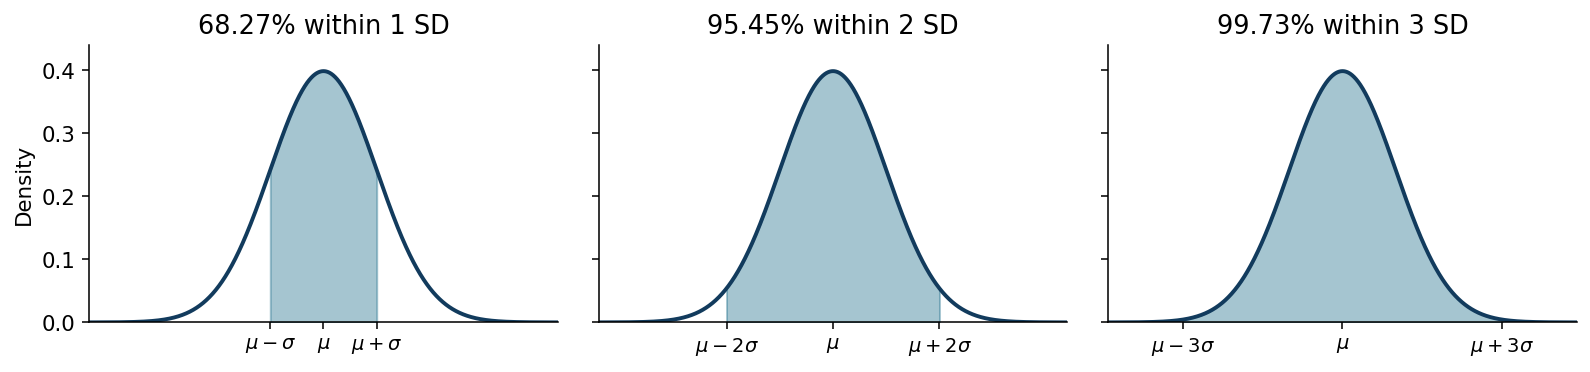

If fill volume has $\mu=500$ ml and $\sigma=8$ ml:

* About 68.27% lies between $492$ and $508$ ml.
* About 95.45% lies between $484$ and $516$ ml.
* About 99.73% lies between $476$ and $524$ ml.

These percentages rely on the normal model, not merely on knowing the mean and standard deviation.

---

### Standard Normal Distribution

For $X\sim N(\mu,\sigma^2)$,

$$Z=\frac{X-\mu}{\sigma}\sim N(0,1).$$

* $z$: number of standard deviations a value lies above or below the mean.
* Positive $z$: above the mean; negative $z$: below the mean.
* Standardization changes the scale, not the probability of the corresponding event.

For fill volume with $\mu=500$ ml and $\sigma=8$ ml:

$$x=512\quad\Longrightarrow\quad z=\frac{512-500}{8}=1.50.$$

$$P(X\leq512)=P\left(\frac{X-500}{8}\leq\frac{512-500}{8}\right)
=P(Z\leq1.50).$$

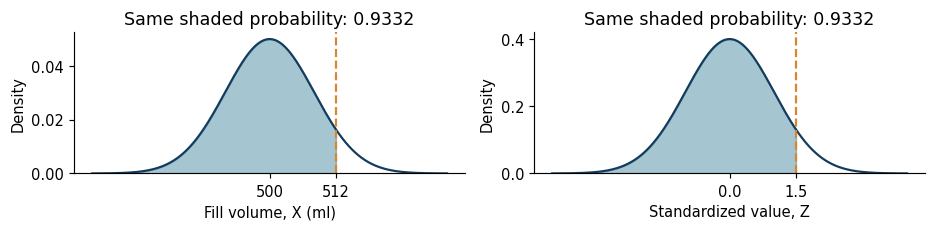

---

### Standard Normal Table

The cumulative standard normal table gives the area to the left:

$$\Phi(z)=P(Z\leq z).$$

Excerpt from a cumulative table:

| $z$ | .00 | .01 | .02 | .03 | .04 | .05 | .06 |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 1.0 | 0.8413 | 0.8438 | 0.8461 | 0.8485 | 0.8508 | 0.8531 | 0.8554 |
| 1.5 | 0.9332 | 0.9345 | 0.9357 | 0.9370 | 0.9382 | 0.9394 | 0.9406 |
| 1.6 | 0.9452 | 0.9463 | 0.9474 | 0.9484 | 0.9495 | 0.9505 | 0.9515 |
| 1.9 | 0.9713 | 0.9719 | 0.9726 | 0.9732 | 0.9738 | 0.9744 | 0.9750 |
| 2.0 | 0.9772 | 0.9778 | 0.9783 | 0.9788 | 0.9793 | 0.9798 | 0.9803 |

* Row: units and tenths of $z$.
* Column: hundredths of $z$.

For $z=1.53$, use row $1.5$ and column $.03$:

$$P(Z\leq1.53)=\Phi(1.53)\approx0.9370.$$

Symmetry gives negative values; complements give right tails:

$$\Phi(-1.50)=1-\Phi(1.50)\approx1-0.9332=0.0668,$$

$$P(Z>1.50)=1-\Phi(1.50)\approx0.0668.$$

For values outside this excerpt, use the full cumulative normal table or Excel `=NORM.S.DIST(z,TRUE)`. For example, `=NORM.S.DIST(2.5,TRUE)` gives $\Phi(2.50)\approx0.9938$.

---

### Normal Probabilities: Fill Volume

Gamma Bottling models fill volume $X$ as normal.

| Mean, $\mu$ | Standard deviation, $\sigma$ |
|---:|---:|
| 500 ml | 8 ml |

$$z_{492}=\frac{492-500}{8}=-1,\qquad
z_{512}=\frac{512-500}{8}=1.50.$$

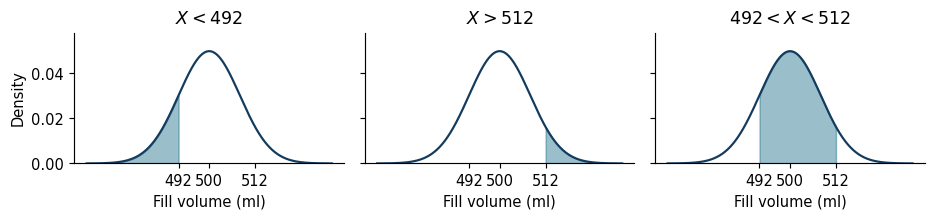

$$P(X<492)=\Phi(-1)\approx1-0.8413=0.1587.$$

$$P(X>512)=1-\Phi(1.50)\approx1-0.9332=0.0668.$$

$$P(492<X<512)=\Phi(1.50)-\Phi(-1)
\approx0.9332-0.1587=0.7745.$$

Calculations use the rounded table entries.

* Excel: `=NORM.DIST(492,500,8,TRUE)` gives $P(X\leq492)\approx0.158655$.
* `TRUE` returns cumulative probability; `FALSE` returns density height, not $P(X=x)$.

---

### Normal Probabilities: Fill Volume

$X\sim N(500,8^2)$; volume in ml. Run this cell to change the event.

$$z_L=\frac{492-500}{8}=-1,\qquad z_U=\frac{512-500}{8}=1.5.$$

$$P(492\leq X\leq 512)=\Phi(1.5)-\Phi(-1)\approx 0.933193-0.158655\approx 0.774538\quad(77.45\%).$$

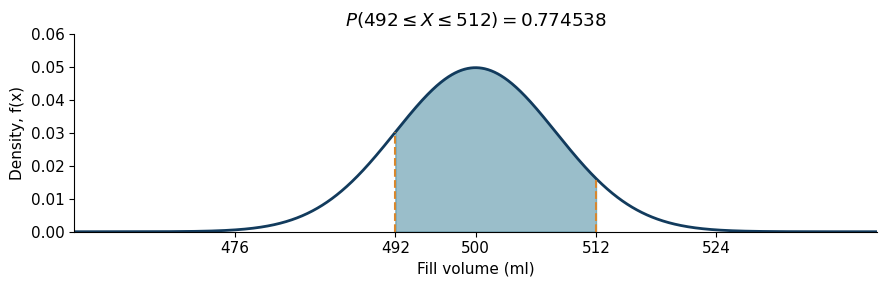

In [1]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from IPython.display import display, Markdown

def normal_fill_probability(kind, cutoff=512, lower=492, upper=512):
    mu, sigma = 500, 8
    z = (cutoff-mu)/sigma
    zl, zu = (lower-mu)/sigma, (upper-mu)/sigma
    if kind == "between":
        return norm.cdf(zu)-norm.cdf(zl)
    if kind == "outside":
        return norm.cdf(zl)+norm.sf(zu)
    if kind == "le":
        return norm.cdf(z)
    if kind == "ge":
        return norm.sf(z)
    return 0.0

def normal_number(value, decimals=6):
    if 0 < abs(value) < 10**(-decimals):
        mantissa, exponent = f"{value:.3e}".split("e")
        return rf"{mantissa}\times10^{{{int(exponent)}}}"
    return f"{value:.{decimals}f}"

def normal_fill_explorer():
    mu, sigma = 500, 8
    style = {"description_width": "initial"}
    formulation = widgets.Dropdown(
        options=[("Between two volumes", "between"),
                 ("At most a specified volume", "le"),
                 ("At least a specified volume", "ge"),
                 ("Outside two volumes", "outside"),
                 ("Exactly a specified volume", "eq")],
        value="between", description="Event:", style=style,
        layout=widgets.Layout(width="430px", max_width="100%"))
    cutoff = widgets.IntSlider(
        value=512, min=468, max=532, description="Volume (ml):",
        continuous_update=False, style=style)
    bounds = widgets.IntRangeSlider(
        value=(492,512), min=468, max=532, description="Volumes (ml):",
        continuous_update=False, style=style)
    display(widgets.VBox([formulation, cutoff, bounds]))
    calculation_display = display(Markdown(""), display_id=True)
    graph_display = display(Markdown(""), display_id=True)

    def update(change=None):
        kind, k = formulation.value, cutoff.value
        lo, hi = bounds.value
        is_range = kind in ("between","outside")
        cutoff.layout.display = "none" if is_range else ""
        bounds.layout.display = "" if is_range else "none"
        z, zl, zu = (k-mu)/sigma, (lo-mu)/sigma, (hi-mu)/sigma
        x = np.linspace(460,540,2001)
        if kind == "between":
            event = rf"{lo}\leq X\leq {hi}"
            expression = rf"\Phi({zu:g})-\Phi({zl:g})"
            numbers = f"{normal_number(norm.cdf(zu))}-{normal_number(norm.cdf(zl))}"
            mask = (x >= lo) & (x <= hi)
        elif kind == "outside":
            event = rf"X<{lo}\ \mathrm{{or}}\ X>{hi}"
            expression = rf"\Phi({zl:g})+[1-\Phi({zu:g})]"
            numbers = f"{normal_number(norm.cdf(zl))}+[1-{normal_number(norm.cdf(zu))}]"
            mask = (x < lo) | (x > hi)
        elif kind == "le":
            event, expression = rf"X\leq{k}", rf"\Phi({z:g})"
            numbers = normal_number(norm.cdf(z))
            mask = x <= k
        elif kind == "ge":
            event, expression = rf"X\geq{k}", rf"1-\Phi({z:g})"
            numbers = f"1-{normal_number(norm.cdf(z))}"
            mask = x >= k
        else:
            event, expression, numbers = rf"X={k}", "0", "0"
            mask = np.zeros_like(x, dtype=bool)
        probability = normal_fill_probability(kind,k,lo,hi)
        lines = ["### Normal Probabilities: Fill Volume",
                 r"$X\sim N(500,8^2)$; volume in ml. Run this cell to change the event."]
        if is_range:
            lines.append(rf"$$z_L=\frac{{{lo}-500}}{{8}}={zl:g},"
                         rf"\qquad z_U=\frac{{{hi}-500}}{{8}}={zu:g}.$$")
        else:
            lines.append(rf"$$z=\frac{{{k}-500}}{{8}}={z:g}.$$")
        if kind == "eq":
            lines.append(rf"$$P({event})=0.$$")
            lines.append("An exact volume has zero probability under the continuous model.")
        else:
            lines.append(rf"$$P({event})={expression}\approx {numbers}"
                         rf"\approx {normal_number(probability)}\quad({normal_number(100*probability, 2)}\%).$$")
        calculation_display.update(Markdown("\n\n".join(lines)))
        with plt.rc_context({"font.size":11,"axes.spines.top":False,
                             "axes.spines.right":False}):
            fig, ax = plt.subplots(figsize=(9,3))
            y = norm.pdf(x,mu,sigma)
            ax.plot(x,y,color="#123b5d",lw=2)
            ax.fill_between(x,0,y,where=mask,color="#1f6f8b",alpha=.45)
            for value in ([lo,hi] if is_range else [k]):
                ax.vlines(value,0,norm.pdf(value,mu,sigma),color="#d8872d",ls="--")
            ax.set(xlim=(460,540),ylim=(0,.06),xlabel="Fill volume (ml)",
                   ylabel="Density, f(x)",title=rf"$P({event})={normal_number(probability)}$")
            ax.set_xticks(sorted(set([476,500,524]+([lo,hi] if is_range else [k]))))
            fig.tight_layout()
            graph_display.update(fig)
            plt.close(fig)

    for control in (formulation,cutoff,bounds):
        control.observe(update,names="value")
    update()
    return formulation,cutoff,bounds

normal_controls = normal_fill_explorer()

### Exercise 2

Delta Bottling models fill volume $X$ as normal. A bottle is rejected if its fill volume is outside the specification limits.

| Mean | Standard deviation | Lower specification limit | Upper specification limit |
|---:|---:|---:|---:|
| 250 ml | 4 ml | 242 ml | 256 ml |

a. Find the probabilities of rejection below the lower limit and above the upper limit. What proportion of bottles meets both limits?

b. In a batch of 1,000 bottles, how many rejections are expected? Explain why the expected number need not equal the observed number.

---

### Normal Percentiles

A percentile reverses the probability calculation: the probability is given and the cutoff is unknown.

Let $x_p$ have cumulative probability $p$, where $p$ is written as a proportion:

$$P(X\leq x_p)=p.$$

Find $z$ such that $\Phi(z)=p$, then return to the original units:

$$z=\frac{x_p-\mu}{\sigma}
\quad\Longrightarrow\quad \sigma z=x_p-\mu
\quad\Longrightarrow\quad x_p=\mu+\sigma z.$$

| Percentile | Cumulative probability, $p$ | $z$ |
|---|---:|---:|
| 5th | 0.05 | $-1.645$ |
| 50th | 0.50 | $0$ |
| 90th | 0.90 | $1.282$ |
| 95th | 0.95 | $1.645$ |

The table gives approximate $z$ values. A 5% upper tail requires cumulative probability $0.95$, not $0.05$.

For the 95th percentile, look for $0.9500$ inside the cumulative table:

$$\Phi(1.64)\approx0.9495,\qquad \Phi(1.65)\approx0.9505.$$

The target is halfway between these entries, so interpolate:

$$z\approx1.64+
\frac{0.9500-0.9495}{0.9505-0.9495}(1.65-1.64)=1.645.$$

Excel `=NORM.S.INV(0.95)` gives $1.644854$. Replace $0.95$ with the required cumulative probability for other percentiles.

---

### Normal Percentiles: Reorder Point

Theta Chemicals places a replenishment order when inventory reaches $r$ litres. Demand $D$ before that order arrives is normal.

| Mean demand | Standard deviation | Maximum stockout probability |
|---:|---:|---:|
| 120 litres | 15 litres | 0.05 |

A stockout occurs if demand exceeds the inventory available:

$$P(D>r)\leq0.05
\quad\Longleftrightarrow\quad P(D\leq r)\geq0.95.$$

The smallest qualifying reorder point is the 95th percentile. Find $z$ such that $\Phi(z)=0.95$:

$$z\approx1.645,\qquad
r=120+15z\approx144.7\text{ litres}.$$

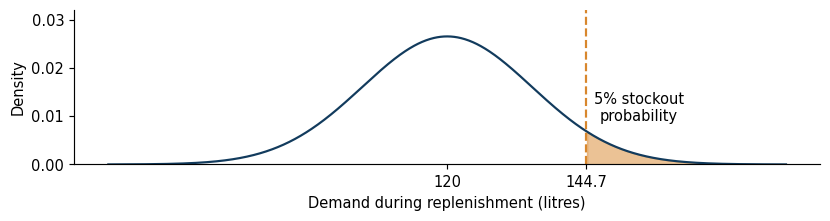

Excel: `=NORM.INV(0.95,120,15)` gives $144.6728$ litres.

---

### Central Normal Intervals

For the central 95% of a normal distribution:

* Probability outside the interval: $1-0.95=0.05$.
* Each tail: $0.05/2=0.025$.
* Cumulative probabilities at the endpoints: $0.025$ and $0.975$.

$$\Phi(-1.96)\approx0.025,\qquad \Phi(1.96)\approx0.975.$$

$$P(\mu-1.96\sigma\leq X\leq\mu+1.96\sigma)\approx0.95.$$

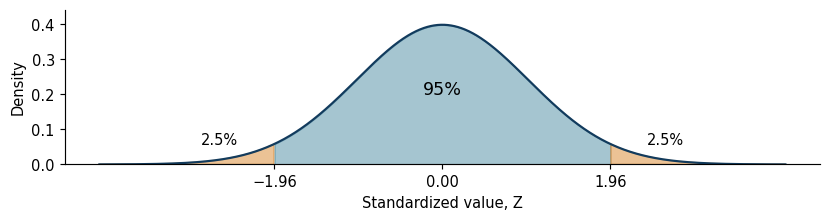

For Gamma's fill volume, $\mu=500$ ml and $\sigma=8$ ml:

$$500\pm1.96(8)\quad\Longrightarrow\quad[484.32,\ 515.68]\text{ ml}.$$

This interval describes individual fill volumes, not uncertainty about the population mean.

---

### Exercise 3

Sigma Foods models package weight $X$ as normal. It wants no more than 2.5% of packages to weigh less than the minimum weight printed on the label.

| Mean weight | Standard deviation | Proposed labelled minimum |
|---:|---:|---:|
| 1,000 g | 20 g | 970 g |

a. Find the largest minimum weight, in whole grams, that the company can print while meeting the 2.5% requirement.

b. Does the proposed 970 g label meet the requirement? Quantify the difference.

---

### Student's $t$-Distribution

* Symmetric about zero, with heavier tails than the standard normal distribution.
* Shape depends on degrees of freedom, written $df$.
* As $df$ increases, the $t$-distribution approaches the standard normal distribution.

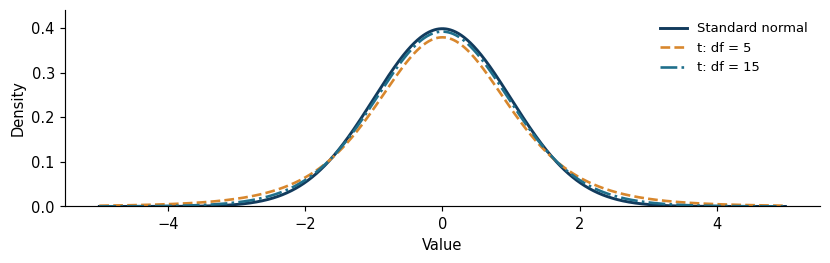

We will use $t$ for inference about a population mean when $\sigma$ is unknown and is estimated using the sample standard deviation, $s$.

For the one-sample procedures we will study:

$$df=n-1,\qquad n=\text{sample size}.$$

Calculations follow after sampling distributions.

---

### Normal Approximation to the Binomial Distribution

For $X\sim\operatorname{Bin}(n,p)$, a normal distribution can approximate binomial probabilities when

$$np\geq5,\qquad n(1-p)\geq5.$$

Both the expected number of successes and the expected number of failures must be sufficiently large.

Use a continuous variable $Y$ with the same mean and variance:

$$Y\sim N\bigl(np,\ np(1-p)\bigr),$$

$$\mu=np,\qquad \sigma^2=np(1-p),\qquad
\sigma=\sqrt{np(1-p)}.$$

* $X$: an integer count; $Y$: a continuous approximation.
* Large $n$ alone is insufficient when $p$ is close to $0$ or $1$.
* The conditions are a guideline, not a guarantee of accurate tail probabilities.

---

### Continuity Correction

Let $X$ count purchases among 100 customers, each independently buying with probability $0.50$:

$$X\sim\operatorname{Bin}(100,0.50),\qquad Y\sim N(50,5^2).$$

* $X$ takes integer values; $Y$ is continuous. A single point has no area under the normal curve, so $P(Y=58)=0$ even though $P(X=58)>0$.
* Draw each binomial bar centered at $x$, with width $1$ and height $P(X=x)$. Its area is $1\times P(X=x)=P(X=x)$.
* Approximate this bar's area using the normal area over the same interval. The bar edges are $x-0.5$ and $x+0.5$: this is why we adjust by $0.5$.

Exactly 58 purchases: the bar is centered at $58$ and extends half a unit on each side, from $57.5$ to $58.5$:

$$P(X=58)\approx P(57.5<Y<58.5).$$

At least 58 purchases: include $58,59,60,\ldots$. Start at $57.5$ to include the entire bar for $58$ and every bar to its right:

$$P(X\geq58)\approx P(Y>57.5).$$

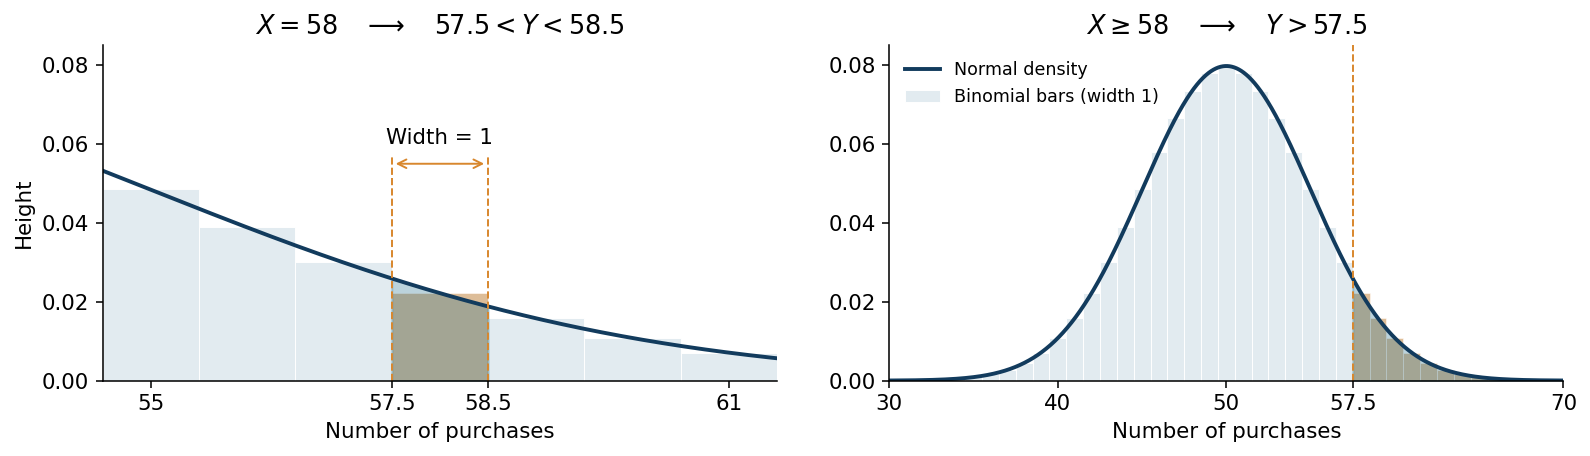

* Using $Y>58$ would start at the center of the first included bar, omitting its left half. Use $Y>57.5$ to include the whole bar.

---

### Continuity Correction: Events

Let $X$ be the binomial count and $Y$ its normal approximation. The cutoffs below are integers.

| Wording | Binomial event | Normal event |
|---|---|---|
| Exactly $k$ | $X=k$ | $k-0.5<Y<k+0.5$ |
| At most $k$ | $X\leq k$ | $Y<k+0.5$ |
| Fewer than $k$ | $X<k$ | $Y<k-0.5$ |
| At least $k$ | $X\geq k$ | $Y>k-0.5$ |
| More than $k$ | $X>k$ | $Y>k+0.5$ |
| Between $r$ and $s$, inclusive | $r\leq X\leq s$ | $r-0.5<Y<s+0.5$ |

For example, more than 58 means 59 or more:

$$P(X>58)=P(X\geq59)\approx P(Y>58.5).$$

Translate the count event first, then adjust the boundaries and standardize.

---

### Normal Approximation: Purchases

Lambda Retail contacts 100 customers. Purchase decisions are independent, each with probability $0.50$. Let $X$ count purchases.

| $n$ | $p$ | $\mu=np$ | $\sigma=\sqrt{np(1-p)}$ |
|---:|---:|---:|---:|
| 100 | 0.50 | 50 | 5 |

Both expected counts are $50\geq5$. Find the probability of at least 58 purchases.

$$P(X\geq58)\approx P(Y>57.5),\qquad Y\sim N(50,5^2).$$

$$z=\frac{57.5-50}{5}=1.50.$$

$$P(X\geq58)\approx1-\Phi(1.50)\approx1-0.9332=0.0668.$$

| Method | Event evaluated | Probability |
|---|---|---:|
| Exact binomial | $X\geq58$ | 0.066605 |
| Normal with continuity correction | $Y>57.5$ | 0.066807 |
| Normal without continuity correction | $Y>58$ | 0.054799 |

Comparison values use software. The corrected approximation is much closer to the exact probability in this example.

---

### Exercise 4

Omega Support contacts 100 customers. Each independently needs technical assistance with probability $0.10$. Let $X$ count customers needing assistance.

| Customers contacted | Probability of needing assistance | Plan A capacity | Plan B capacity |
|---:|---:|---:|---:|
| 100 | 0.10 | 14 customers | 17 customers |

Use the normal approximation.

a. Verify that the approximation conditions hold. Calculate the mean and standard deviation of $X$.

b. Find the probability that between 9 and 17 customers, inclusive, need assistance.

c. The probability that demand exceeds the chosen plan's capacity should be no greater than 2%. Evaluate both plans and select the smaller capacity that meets this requirement.

---

### Exponential Probability Distribution

The exponential distribution models nonnegative times or distances, such as the time between arrivals.

For a waiting time $T$ with mean $\mu>0$,

$$f(t)=
\begin{cases}
\dfrac1\mu e^{-t/\mu}, & t\geq0,\\
0, & t<0.
\end{cases}$$

* Right-skewed: short times have higher density; long times remain possible.
* The total area under the curve is $1$.
* A positive waiting time is not automatically exponential; the model must suit the process.

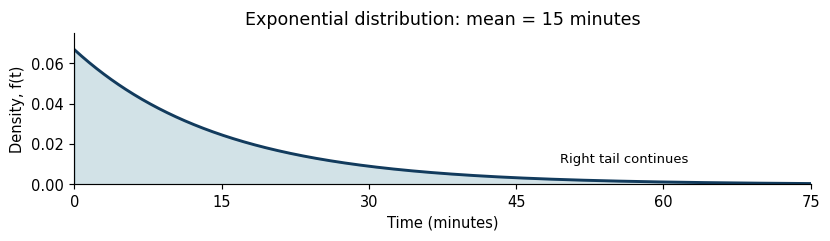

---

### Exponential Mean and Variance

For an exponential waiting time with mean $\mu$,

$$E(T)=\mu,\qquad \operatorname{Var}(T)=\mu^2,\qquad \sigma_T=\mu.$$

The mean and standard deviation are equal.

If the mean loading time is 15 minutes:

$$E(T)=15\text{ minutes},\qquad
\operatorname{Var}(T)=15^2=225\text{ minutes}^2,\qquad
\sigma_T=15\text{ minutes}.$$

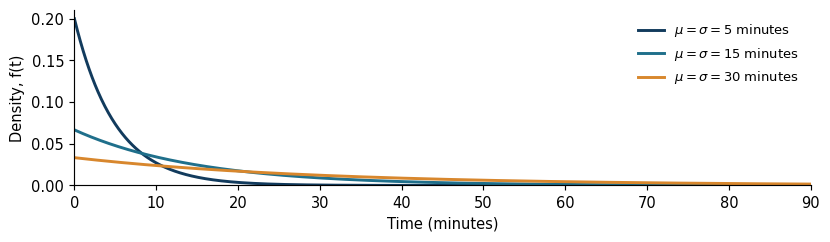

A larger mean spreads the distribution further to the right and increases the standard deviation.

---

### Exponential Probabilities

For an exponential waiting time $T$ with mean $\mu$, the cumulative probability is

$$F(t)=P(T\leq t)=1-e^{-t/\mu},\qquad t\geq0.$$

More than $t$ units of time:

$$P(T>t)=1-F(t)=1-(1-e^{-t/\mu})=e^{-t/\mu}.$$

Between $a$ and $b$, where $0\leq a<b$:

$$P(a<T\leq b)=F(b)-F(a)$$

$$P(a<T\leq b)=(1-e^{-b/\mu})-(1-e^{-a/\mu})
=e^{-a/\mu}-e^{-b/\mu}.$$

* Express $t$ and $\mu$ in the same time unit.
* At $t=0$: $P(T\leq0)=0$ and $P(T>0)=1$.
* As $t$ increases, $P(T\leq t)$ increases and $P(T>t)$ decreases.

---

### Exponential Probabilities: Loading Time

Nu Logistics models truck loading time $T$ as exponential.

| Variable | Mean, $\mu$ |
|---|---:|
| Loading time in minutes | 15 minutes |

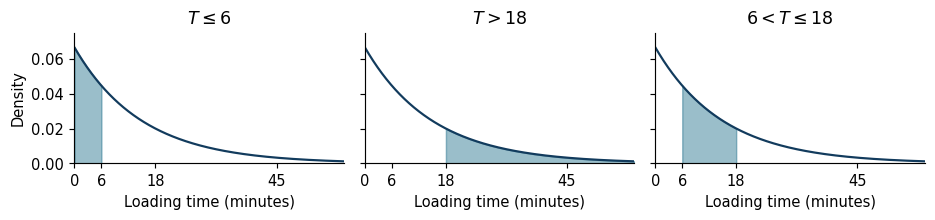

Within 6 minutes:

$$P(T\leq6)=1-e^{-6/15}\approx1-0.6703=0.3297.$$

More than 18 minutes:

$$P(T>18)=e^{-18/15}\approx0.3012.$$

Between 6 and 18 minutes:

$$P(6<T\leq18)=e^{-6/15}-e^{-18/15}
\approx0.6703-0.3012=0.3691.$$

* Excel: `=EXPON.DIST(6,1/15,TRUE)` gives $P(T\leq6)\approx0.329680$.
* Second argument: rate $1/\mu$, not mean $\mu$. `TRUE` returns cumulative probability; `FALSE` returns density height.

---

### Exponential Probabilities: Loading Time

$T$ is exponential with mean $\mu=15$ minutes. Run this cell to change the mean and event.

$$P(6\leq T\leq18)=e^{-6/15}-e^{-18/15}\approx 0.670320-0.301194\approx0.369126\quad(36.91\%).$$

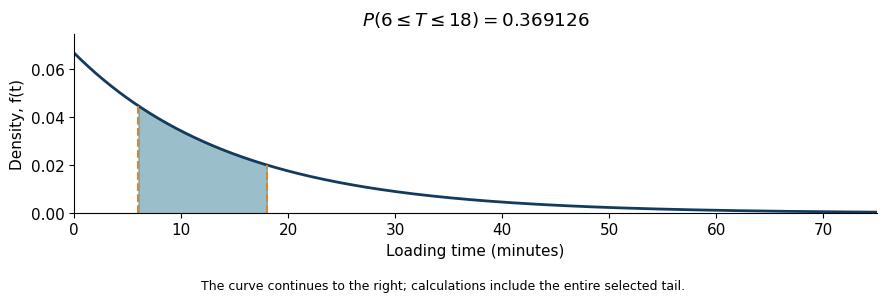

In [1]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from math import exp
from IPython.display import display, Markdown

def exponential_time_probability(kind, mean=15, cutoff=6, lower=6, upper=18):
    if mean <= 0:
        raise ValueError("Mean time must be positive.")
    if min(cutoff, lower, upper) < 0 or lower > upper:
        raise ValueError("Use nonnegative times and an ordered interval.")
    if kind == "between":
        return exp(-lower/mean)-exp(-upper/mean)
    if kind == "outside":
        return 1-exp(-lower/mean)+exp(-upper/mean)
    if kind == "le":
        return 1-exp(-cutoff/mean)
    if kind == "ge":
        return exp(-cutoff/mean)
    if kind == "eq":
        return 0.0
    raise ValueError("Unknown event.")

def exponential_number(value, decimals=6):
    if 0 < abs(value) < 10**(-decimals):
        mantissa, exponent = f"{value:.3e}".split("e")
        return rf"{mantissa}\times10^{{{int(exponent)}}}"
    return f"{value:.{decimals}f}"

def exponential_time_explorer():
    style = {"description_width":"initial"}
    mean = widgets.IntSlider(
        value=15,min=1,max=30,description="Mean time (minutes):",
        continuous_update=False,style=style)
    formulation = widgets.Dropdown(
        options=[("Between two times","between"),
                 ("At most a specified time","le"),
                 ("At least a specified time","ge"),
                 ("Outside two times","outside"),
                 ("Exactly a specified time","eq")],
        value="between",description="Event:",style=style,
        layout=widgets.Layout(width="430px",max_width="100%"))
    cutoff = widgets.IntSlider(
        value=6,min=0,max=90,description="Time (minutes):",
        continuous_update=False,style=style)
    bounds = widgets.IntRangeSlider(
        value=(6,18),min=0,max=90,description="Times (minutes):",
        continuous_update=False,style=style)
    display(widgets.VBox([mean,formulation,cutoff,bounds]))
    calculation_display = display(Markdown(""),display_id=True)
    graph_display = display(Markdown(""),display_id=True)

    def update(change=None):
        mu,kind,k = mean.value,formulation.value,cutoff.value
        lo,hi = bounds.value
        is_range = kind in ("between","outside")
        cutoff.layout.display = "none" if is_range else ""
        bounds.layout.display = "" if is_range else "none"
        xmax = max(5*mu,1.15*(hi if is_range else k),1)
        x = np.unique(np.r_[np.linspace(0,xmax,2001),lo,hi,k])
        if kind == "between":
            event = rf"{lo}\leq T\leq{hi}"
            expression = rf"e^{{-{lo}/{mu}}}-e^{{-{hi}/{mu}}}"
            numbers = f"{exponential_number(exp(-lo/mu))}-{exponential_number(exp(-hi/mu))}"
            mask = (x>=lo)&(x<=hi)
        elif kind == "outside":
            event = rf"T<{lo}\ \mathrm{{or}}\ T>{hi}"
            expression = rf"[1-e^{{-{lo}/{mu}}}]+e^{{-{hi}/{mu}}}"
            numbers = f"[1-{exponential_number(exp(-lo/mu))}]+{exponential_number(exp(-hi/mu))}"
            mask = (x<lo)|(x>hi)
        elif kind == "le":
            event,expression = rf"T\leq{k}",rf"1-e^{{-{k}/{mu}}}"
            numbers = f"1-{exponential_number(exp(-k/mu))}"
            mask = x<=k
        elif kind == "ge":
            event,expression = rf"T\geq{k}",rf"e^{{-{k}/{mu}}}"
            numbers = exponential_number(exp(-k/mu))
            mask = x>=k
        else:
            event,expression,numbers = rf"T={k}","0","0"
            mask = np.zeros_like(x,dtype=bool)
        probability = exponential_time_probability(kind,mu,k,lo,hi)
        lines = ["### Exponential Probabilities: Loading Time",
                 rf"$T$ is exponential with mean $\mu={mu}$ minutes. "
                 "Run this cell to change the mean and event."]
        if kind=="eq":
            lines.extend([rf"$$P({event})=0.$$",
                          "An exact time has zero probability under the continuous model."])
        else:
            lines.append(rf"$$P({event})={expression}\approx {numbers}"
                         rf"\approx{exponential_number(probability)}\quad({exponential_number(100*probability, 2)}\%).$$")
        calculation_display.update(Markdown("\n\n".join(lines)))
        with plt.rc_context({"font.size":11,"axes.spines.top":False,
                             "axes.spines.right":False}):
            fig,ax = plt.subplots(figsize=(9,3))
            y = np.exp(-x/mu)/mu
            ax.plot(x,y,color="#123b5d",lw=2)
            ax.fill_between(x,0,y,where=mask,color="#1f6f8b",alpha=.45)
            for value in ([lo,hi] if is_range else [k]):
                ax.vlines(value,0,exp(-value/mu)/mu,color="#d8872d",ls="--")
            ax.set(xlim=(0,xmax),ylim=(0,1.12/mu),xlabel="Loading time (minutes)",
                   ylabel="Density, f(t)",title=rf"$P({event})={exponential_number(probability)}$")
            fig.text(.5,.01,"The curve continues to the right; calculations include the entire selected tail.",
                     ha="center",fontsize=9)
            fig.tight_layout(rect=(0,.06,1,1))
            graph_display.update(fig)
            plt.close(fig)

    for control in (mean,formulation,cutoff,bounds):
        control.observe(update,names="value")
    update()
    return mean,formulation,cutoff,bounds

exponential_controls = exponential_time_explorer()

### Poisson and Exponential Distributions

Suppose arrivals follow a Poisson process with constant rate $\lambda$ and independent counts in nonoverlapping intervals.

* $N(t)$: number of arrivals in an interval of length $t$.
* $T$: time from the start of observation until the next arrival.
* No arrival by time $t$ means $N(t)=0$.

$$N(t)\sim\operatorname{Pois}(\lambda t),\qquad
P(T>t)=P(N(t)=0)=e^{-\lambda t}.$$

Compare this with $P(T>t)=e^{-t/\mu}$:

$$\lambda=\frac1\mu
\quad\Longrightarrow\quad E(T)=\mu=\frac1\lambda.$$

Example: 12 calls per hour.

$$\lambda=\frac{12}{60}=0.20\text{ calls per minute},\qquad
E(T)=\frac1{0.20}=5\text{ minutes}.$$

In 10 minutes, the expected count is $0.20(10)=2$:

$$P(T>10)=P(N(10)=0)=\frac{2^0e^{-2}}{0!}
=e^{-2}\approx0.1353.$$

The expected count is 2 calls; the mean waiting time is 5 minutes. They are different quantities.

---

### Exercise 5

Rho Helpdesk receives calls according to a Poisson process: the rate is constant, and counts in nonoverlapping intervals are independent.

| Average arrival rate | Start of observation |
|---:|---|
| 8 calls per hour | 9:00 a.m. |

a. What is the probability of exactly two calls between 9:00 and 9:15?

b. What is the probability that the first call after observation begins arrives later than 9:10?

c. What is the probability that the first call after observation begins arrives between 9:05 and 9:15?

---

### What is next?

* Sampling and Sampling Distributions I
  * The Electronics Associates Sampling Problem
  * Selecting a Sample
  * Point Estimation
  * Introduction to Sampling Distributions

Reading(s): SBE Sections 7.1–7.4

---

### Exercise 6

Tau Equipment must choose how to sell a used machine. Under the broker option, the selling fee is fixed and deducted from the final sale price.

| Option | Gross sale proceeds | Selling fee |
|---|---|---:|
| Immediate sale | Guaranteed 84,000 MAD | 0 MAD |
| Broker sale | Uniformly distributed between 80,000 and 100,000 MAD | 4,000 MAD |

There are no other costs. The company's risk policy is:

| Net proceeds floor | Maximum probability of falling below the floor |
|---:|---:|
| 80,000 MAD | 10% |

a. Compare the expected net proceeds and standard deviation under the two options.

b. For the broker option, calculate the probability of receiving less than the immediate-sale amount and the probability of falling below the policy floor.

c. Recommend an option under the current terms. If the broker's fee can be negotiated, find the largest fixed fee that would make the broker option satisfy the policy.

---

### Exercise 7

Upsilon Components can use either of two production processes. Component diameter is normally distributed under each process.

| Process | Mean diameter | Standard deviation |
|---|---:|---:|
| A | 100 mm | 2 mm |
| B | 101 mm | 1 mm |

| Lower specification limit | Upper specification limit | Maximum rejection rate |
|---:|---:|---:|
| 97 mm | 103 mm | 1% |

Components outside the specification limits are rejected. Either process's mean can be adjusted without changing its standard deviation.

Use a cumulative normal table or Excel. For table-based calculations, take $\Phi(-4)\approx0$; small rounding differences are acceptable.

a. Calculate the rejection rate under each process's current settings.

b. Choose a process and mean setting that meet the 1% requirement without changing the standard deviation. Explain why adjusting the other process's mean is insufficient.

c. With the mean set to 100 mm, find the largest standard deviation compatible with the 1% requirement.

---

### Exercise 8

Phi Training invites 100 customers to a workshop. Each independently attends with probability $0.10$.

The company must choose a kit-delivery plan. Time $T$ from dispatch to delivery follows an exponential distribution with the mean shown below. Under each plan, delivery time is independent of the number of attendees.

| Plan | Kits delivered | Mean delivery time | Fixed plan cost |
|---|---:|---:|---:|
| A | 14 | 10 minutes | 180 MAD |
| B | 17 | 10 minutes | 210 MAD |
| C | 14 | 5 minutes | 220 MAD |
| D | 17 | 5 minutes | 250 MAD |

* Each attendee needs one kit; no extra kits are available.
* The workshop is ready only if enough kits are delivered and delivery occurs within 20 minutes of dispatch.
* Required probability of being ready: at least 90%.
* The stated plan cost is the only cost for this comparison.

Select the least expensive qualifying plan and justify your recommendation numerically. Use the normal approximation for the attendance count.

---